# 50 Startups 線性迴歸重現
本 Notebook 重現 Akash Singh 的 [Kaggle 專案](https://www.kaggle.com/code/akash17/50-startups-linearregression)，並補上指定圖片的 1～5 個特徵比較，以及五種自動特徵選擇方法。

資料：50 家公司的研發支出、行政費用、行銷支出、所在州與利潤。目標為 `Profit`。

**來源差異：** 原 Notebook 使用全資料標準化與 OLS，沒有附圖的特徵數實驗。附圖設定是經實際計算核對而推得，不能由圖片確認作者原本的選擇程序。全部指標由資料訓練計算，沒有把圖片數值當作繪圖資料。

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from reproduce import load_data, compare_features, plot_comparison, original_analysis, format_results_table
OUT = Path('results')
df = load_data()
display(df.head())
print('資料維度：', df.shape)
print('缺漏值：', df.isna().sum().to_dict())
print('重複資料：', df.duplicated().sum())
display(df.describe())

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


資料維度： (50, 5)
缺漏值： {'R&D Spend': 0, 'Administration': 0, 'Marketing Spend': 0, 'State': 0, 'Profit': 0}
重複資料： 0


,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


## 重現指定圖片
`train_test_split(test_size=0.2, random_state=0)`，40 筆訓練、10 筆測試。州別以 California 為參考類別，使用兩個 dummy 欄位，加上三個數值欄位，共五個特徵。

逐次使用前 k 個欄位：`R&D Spend → Marketing Spend → State_New York → State_Florida → Administration`。這是為圖片重現而指定的順序，不是自動特徵選擇演算法。各模型使用相同測試列。

RMSE = √mean((y − ŷ)²)；R² = 1 − Σ(y − ŷ)² / Σ(y − mean(y))²。

|   Number of Features | Selected Features                                                         |    RMSE |   R-squared |
|----------------------|---------------------------------------------------------------------------|---------|-------------|
|                    1 | R&D Spend                                                                 | 8274.87 |    0.946459 |
|                    2 | R&D Spend, Marketing Spend                                                | 8198.80 |    0.947439 |
|                    3 | R&D Spend, Marketing Spend, State_New York                                | 8309.06 |    0.946015 |
|                    4 | R&D Spend, Marketing Spend, State_New York, State_Florida                 | 8409.92 |    0.944697 |
|                    5 | R&D Spend, Marketing Spend, State_New York, State_Florida, Administration | 9137.99 |    0.934707 |

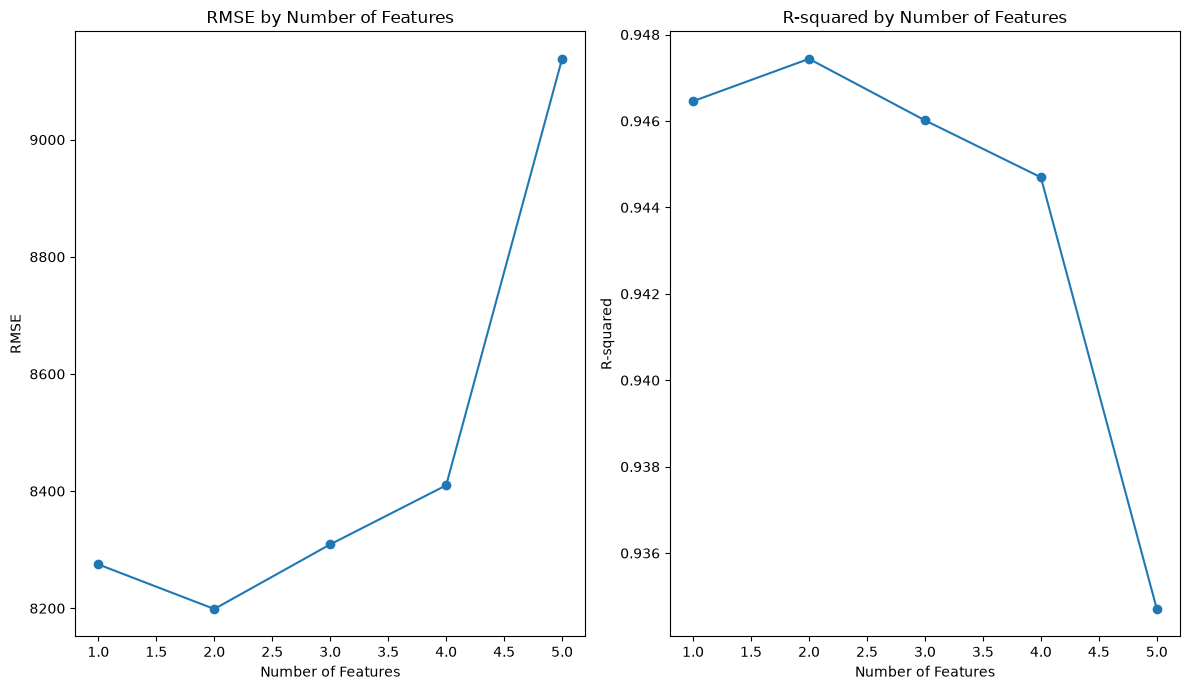

In [2]:
metrics = compare_features(df, OUT)
reference_markdown = format_results_table(metrics)
display(Markdown(reference_markdown))
(OUT / 'feature_results.md').write_text(reference_markdown + '\n')
fig = plot_comparison(metrics, OUT)
plt.show()

## 原專案的 OLS 分析與診斷
保留原始流程的標準化、全特徵／研發單變數／研發與行銷雙變數 OLS、Cook's distance，以及刪除第 49 列後的研發模型。

原版把三個州 dummy 全部與截距同時加入，會造成完全共線性；此處省略 California，維持相同擬合空間與 R²。下列為**訓練內指標**，不可與前面的測試指標混用。刪除第 49 列只用於重現原版分析，附圖的實驗保留全部 50 筆資料。

,model,n_obs,R_squared_train,adjusted_R_squared,AIC
0,full,50,0.950752,0.945156,3.349036
1,RD,50,0.946535,0.945421,-0.542845
2,RD_and_Marketing,50,0.950450,0.948342,-2.345102
3,RD_without_row_49,49,0.957340,0.956432,-16.867542


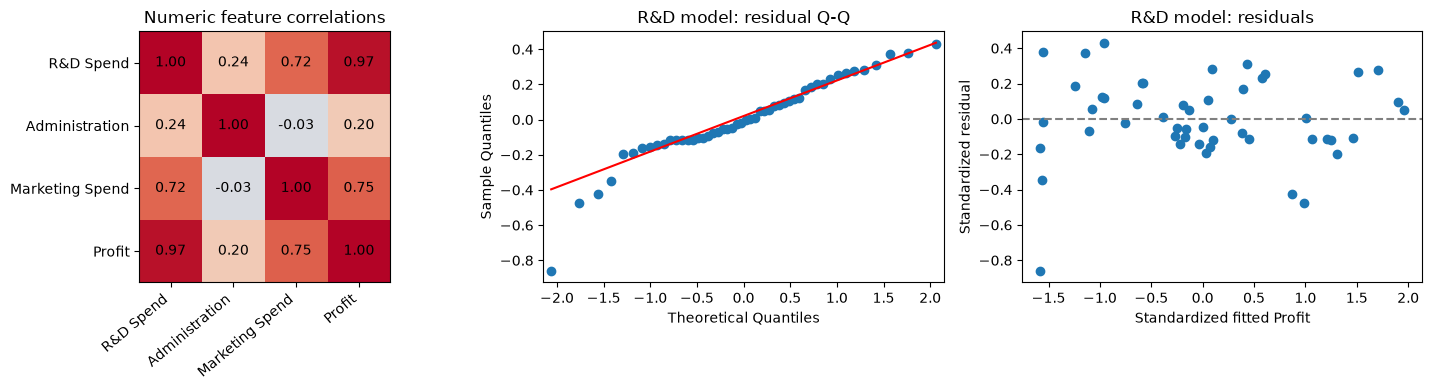

,row_id,cooks_distance
49,49,0.562061
45,45,0.105298
48,48,0.089890
14,14,0.089040
36,36,0.071649


full
                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.951
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     169.9
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           1.34e-27
Time:                        19:44:59   Log-Likelihood:                 4.3255
No. Observations:                  50   AIC:                             3.349
Df Residuals:                      44   BIC:                             14.82
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const           -5.031e-16      0.033

In [3]:
summaries, fig, example = original_analysis(df, OUT)
display(summaries)
plt.show()
display(pd.read_csv(OUT / 'influence.csv').sort_values('cooks_distance', ascending=False).head())
print((OUT / 'ols_summary.txt').read_text())

## 原單位預測
原 Notebook 的模型使用標準化資料，直接輸入原始 `RD=100000` 會造成尺度不一致。此版本先轉換輸入，再把預測 Profit 還原為原始單位。

In [4]:
print(example)

{'RD_input': 100000, 'predicted_profit': 134507.81422098508}


## 原附圖實驗的結論與限制
本次固定切分中，研發與行銷兩個特徵得到最低 RMSE（約 8198.80）與最高 R²（約 0.94744），符合附圖。加入其他欄位後的測試表現下降。

這項比較使用圖片核對過的順序與單次小型測試集，因此不能據此宣稱兩特徵模型在新資料上一定最佳；若要選擇正式模型，應在訓練資料內做交叉驗證並保留獨立測試集。

`results/` 內含圖、指標、每個測試列的預測、切分列號、模型係數及 OLS 診斷。

## 五種自動特徵選擇
新增 **Exhaustive、Forward、Backward、RFECV、Lasso**，與上方手動指定的特徵順序分開。

共用原本 40 筆訓練、10 筆測試切分。僅在 40 筆訓練內進行 5-fold CV（shuffle=True、random_state=42），以**各折 RMSE 的算術平均最小**選擇特徵或超參數。每一次 CV 的 StandardScaler 都只 fit 該折訓練資料。Profit 不標準化。

|方法|實作|
|---|---|
|Exhaustive|評估全部 31 種非空組合|
|Forward|每步搜尋最佳新增欄位，走完 1～5 個特徵，再選路徑上 CV 最佳的大小|
|Backward|從 5 個特徵開始，每步移除一欄，走到 1 個，再選路徑上 CV 最佳的大小|
|RFECV|以標準化線性迴歸係數遞迴刪除特徵，CV 決定保留數量|
|Lasso|在 Pipeline 內標準化，用 GridSearchCV 搜尋 61 個 alpha（0.1～100000，等比間隔），保留非零係數；最終預測仍用 Lasso|

State 仍以 California 為基準，兩個 dummy 分開參與選擇；不是把 State 當成不可拆分的群組。

| Method     |   Number of Features | Selected Features                         |    RMSE |   R-squared |
|------------|----------------------|-------------------------------------------|---------|-------------|
| Backward   |                    3 | R&D Spend, Marketing Spend, State_Florida | 8376.45 |    0.945136 |
| Exhaustive |                    3 | R&D Spend, Marketing Spend, State_Florida | 8376.45 |    0.945136 |
| Forward    |                    3 | R&D Spend, Marketing Spend, State_Florida | 8376.45 |    0.945136 |
| Lasso      |                    2 | R&D Spend, Marketing Spend                | 8425.66 |    0.944490 |
| RFECV      |                    2 | R&D Spend, Marketing Spend                | 8198.80 |    0.947439 |

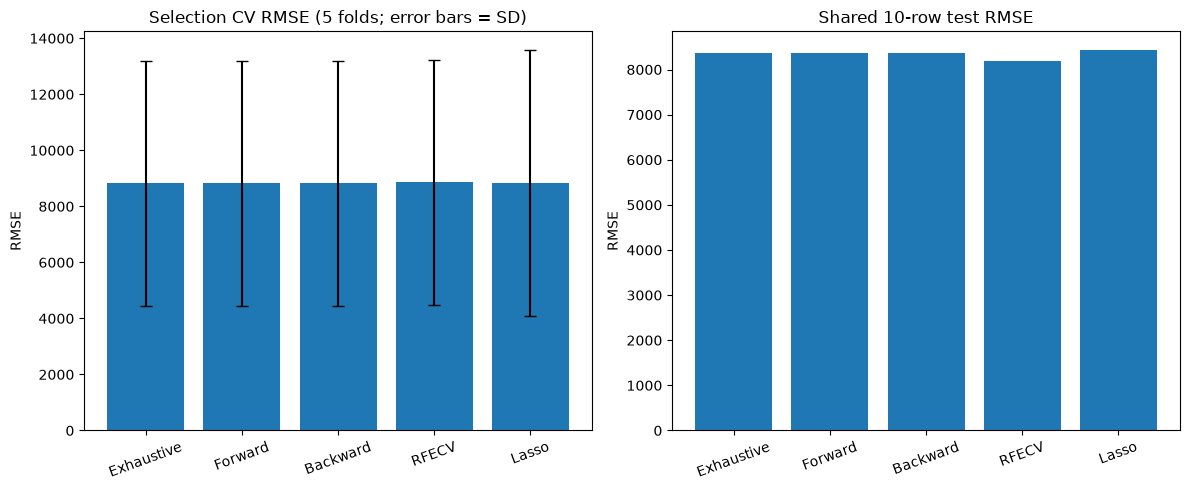

In [5]:
from feature_selection import compare_selection_schemes, plot_selection_comparison
results_df = compare_selection_schemes(df, OUT)
selection = results_df
# format_results_table uses tabulate(..., headers='keys', tablefmt='github').
results_markdown = format_results_table(results_df)
display(Markdown(results_markdown))
(OUT / 'selection_results.md').write_text(results_markdown + '\n')
# 表格依訓練 CV RMSE 排序，沒有使用測試分數挑選方法。
plot_selection_comparison(selection, OUT)
plt.show()

## 選擇過程與可追溯輸出
下表列出各方法在 CV 選定的設定。完整候選組合、逐折 RMSE 與 alpha 搜尋紀錄保存在 `selection_cv_history.csv`；選定的最終特徵則在 `selection_comparison.csv`。

RFECV 在各折內重新刪除特徵，同一個特徵數可能對應不同欄位；Lasso 在各折的非零係數也可能不同，因此歷程表不把它們標成固定特徵組合。RFECV 各折選到的欄位另存於 `selection_protocol.json`。

結果表以 `tabulate` 產生 Markdown，包含 Number of Features、Selected Features、RMSE、R-squared；自動選擇表另加 Method 以辨識方法。RMSE 與 R-squared 使用測試集指標，表格順序仍依訓練 CV RMSE 決定。

In [6]:
history = pd.read_csv(OUT / 'selection_cv_history.csv')
display(history[history['chosen']].reset_index(drop=True))
for row in selection.itertuples():
    print(f'{row.method}: {row.n_features} features — {row.features}')

,method,stage,n_features,features,cv_rmse,cv_rmse_std,alpha,chosen,fold_1_rmse,fold_2_rmse,fold_3_rmse,fold_4_rmse,fold_5_rmse
0,Exhaustive,3,3.0,R&D Spend | Marketing Spend | State_Florida,8825.163711,4380.200654,NaN,True,4989.976272,9749.334804,3401.164730,15839.777690,10145.565057
1,Forward,3,3.0,R&D Spend | Marketing Spend | State_Florida,8825.163711,4380.200654,NaN,True,4989.976272,9749.334804,3401.164730,15839.777690,10145.565057
2,Backward,3,3.0,R&D Spend | Marketing Spend | State_Florida,8825.163711,4380.200654,NaN,True,4989.976272,9749.334804,3401.164730,15839.777690,10145.565057
3,RFECV,2,2.0,(fold-specific RFE subsets),8862.793631,4374.123232,NaN,True,5010.526418,9760.104225,3480.934458,15886.370904,10176.032150
4,Lasso,43,NaN,(nonzero support varies by fold),8831.076332,4738.342442,1584.893192,True,4372.316739,10303.582032,3671.624446,16803.572172,9004.286272


Backward: 3 features — R&D Spend | Marketing Spend | State_Florida
Exhaustive: 3 features — R&D Spend | Marketing Spend | State_Florida
Forward: 3 features — R&D Spend | Marketing Spend | State_Florida
Lasso: 2 features — R&D Spend | Marketing Spend
RFECV: 2 features — R&D Spend | Marketing Spend


## 如何解讀自動選擇結果
前三種方法都選到研發、行銷與 Florida；RFECV 與 Lasso 最終選到研發與行銷。

- `cv_rmse` 是用來挑選組合或超參數的 CV 分數，不是外層 nested CV 的無偏效能估計。誤差棒是五折間標準差，並非信賴區間。
- RFECV 的 CV 分數來自各折內重新選出的欄位，因此不一定等於固定兩特徵組合的 CV 分數。
- Lasso 即使選到與 OLS 相同的欄位，係數仍受正則化影響，測試預測可能不同；沒有在選取後改用 OLS 重訓。
- 10 筆測試資料已在原附圖重現時查看過，現在只作共用比較，不據此再挑方法；不能視為全新的獨立驗證資料。樣本很少，應保留對未來資料效能的不確定性。

執行 `python reproduce.py` 會一次重跑原附圖、五種自動選擇及 OLS 分析。

## 網頁特徵數量曲線
每種方法都有自己的候選曲線，與原附圖的固定順序分開。Exhaustive 逐個特徵數比較訓練 CV；Forward／Backward 使用逐步路徑；RFECV 使用 RFE 路徑；Lasso 依非零係數數量分組後，以訓練 CV 選 alpha。未出現的 Lasso 特徵數不補造。

網頁切換方法或點選資料點時，圖表、指標與特徵會一起更新。所有候選設定先在訓練資料中決定，再顯示同一測試集的結果；不得依測試曲線再挑模型。

In [7]:
curves = pd.read_csv(OUT / 'selection_feature_curves.csv')
display(curves)

,method,n_features,features,cv_rmse,cv_rmse_std,alpha,chosen,test_rmse,test_r_squared
0,Exhaustive,1,R&D Spend,9160.119198,4069.190389,NaN,False,8274.868018,0.946459
1,Exhaustive,2,R&D Spend | Marketing Spend,8862.793631,4374.123232,NaN,False,8198.797191,0.947439
2,Exhaustive,3,R&D Spend | Marketing Spend | State_Florida,8825.163711,4380.200654,NaN,True,8376.450520,0.945136
3,Exhaustive,4,R&D Spend | Administration | Marketing Spend |...,8978.178277,4444.233899,NaN,False,9068.541185,0.935696
4,Exhaustive,5,R&D Spend | Administration | Marketing Spend |...,9231.459045,4580.070505,NaN,False,9137.990153,0.934707
5,Forward,1,R&D Spend,9160.119198,4069.190389,NaN,False,8274.868018,0.946459
6,Forward,2,R&D Spend | Marketing Spend,8862.793631,4374.123232,NaN,False,8198.797191,0.947439
7,Forward,3,R&D Spend | Marketing Spend | State_Florida,8825.163711,4380.200654,NaN,True,8376.450520,0.945136
8,Forward,4,R&D Spend | Administration | Marketing Spend |...,8978.178277,4444.233899,NaN,False,9068.541185,0.935696
9,Forward,5,R&D Spend | Administration | Marketing Spend |...,9231.459045,4580.070505,NaN,False,9137.990153,0.934707
